Naive Bayes

In [36]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import MultinomialNB

# find project folder
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

# load prepped market data 
markets = pd.read_parquet(
    ROOT / "data" / "eda" / "20260916_v2" / "markets.parquet"
)

preview_cols = [
    "market_id",
    "topic",
    "favorite_probability",
    "observed_wallet_count",
    "large_purchase_favorite_share",
    "favorite_change_pp_24h",
]

print(f"markets loaded: {len(markets):,}")
display(markets[preview_cols].head())

markets loaded: 565


,market_id,topic,favorite_probability,observed_wallet_count,large_purchase_favorite_share,favorite_change_pp_24h
0,1003803,Politics,0.7400,287,0.884585,-1.50
1,1004446,Politics,0.9655,3,1.000000,-0.00
2,1004698,Economics,0.9865,48,1.000000,0.00
3,1005027,Economics,0.9945,103,0.988610,-0.35
4,1005383,Economics,0.9995,102,0.996421,0.05


In [37]:
# 1 = favorite won
# 0 = favorite lost
# missing means no favorite at an exact 50/50 forecast

y = pd.Series(
    pd.NA,
    index=markets.index,
    dtype="Int64",
    name="favorite_won",
)

# if outcome 0 favored, use its result
favorite_is_0 = markets["favorite_index"].eq(0)
y.loc[favorite_is_0] = markets.loc[
    favorite_is_0, "outcome_0_result"
]

# if outcome 1 favored, reverse outcome 0's result
favorite_is_1 = markets["favorite_index"].eq(1)
y.loc[favorite_is_1] = 1 - markets.loc[
    favorite_is_1, "outcome_0_result"
]

# inspect the class counts, keep missing 
display(y.value_counts(dropna=False))

favorite_won
1       462
0        85
<NA>     18
Name: count, dtype: Int64

In [38]:
# select initial 5 predictors 
features = [
    "favorite_probability",
    "observed_wallet_count",
    "large_purchase_favorite_share",
    "favorite_change_pp_24h",
    "topic",
]

# remove markets without cutoff favorite 
has_label = y.notna()

X_raw = markets.loc[has_label, features].copy()
y_model = y.loc[has_label].astype(int)

# check dims 
print(f"Markets: {len(X_raw):,}")
print(f"Predictors: {X_raw.shape[1]}")
assert X_raw.index.equals(y_model.index)

# check for missing vals 
display(X_raw.isna().sum().rename("Missing values"))
display(X_raw.head(10))

Markets: 547
Predictors: 5


favorite_probability               0
observed_wallet_count              0
large_purchase_favorite_share    116
favorite_change_pp_24h            40
topic                              0
Name: Missing values, dtype: int64

,favorite_probability,observed_wallet_count,large_purchase_favorite_share,favorite_change_pp_24h,topic
0,0.7400,287,0.884585,-1.50,Politics
1,0.9655,3,1.000000,-0.00,Politics
2,0.9865,48,1.000000,0.00,Economics
3,0.9945,103,0.988610,-0.35,Economics
4,0.9995,102,0.996421,0.05,Economics
5,0.9905,48,1.000000,0.90,Economics
6,0.8485,590,0.828711,-4.50,Economics
7,0.9480,118,0.984775,2.15,Economics
8,0.7750,160,0.741331,2.00,Economics
9,0.8400,168,0.833043,0.00,Economics


In [39]:

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y_model,
    test_size=0.20,
    random_state=14,
    stratify=y_model,
)

# confirm no duplication of markets between train and test 
assert X_train_raw.index.intersection(X_test_raw.index).empty

print(f"training markets: {len(X_train_raw)}")
print(f"testing markets: {len(X_test_raw)}")

# check dist 
display(pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts(),
}))

training markets: 437
testing markets: 110


,Training,Testing
favorite_won,,
1,369,93
0,68,17


In [40]:

bins = {}

# add bins for continuous features in train data 
for column in ["favorite_probability", "observed_wallet_count"]:
    lower, upper = X_train_raw[column].quantile([1/3, 2/3])
    bins[column] = [-np.inf, lower, upper, np.inf]


# apply bins, labels to train and test data
def categorize_features(X):
    categories = pd.DataFrame(index=X.index)

    for column, edges in bins.items():
        categories[column] = pd.cut(
            X[column],
            bins=edges,
            labels=["lower", "middle", "higher"],
        )

    # copy large direction status from markets to flag missing

    share = X["large_purchase_favorite_share"]
    categories["large_purchase_direction"] = markets.loc[
        X.index, "large_purchase_status"
    ]

    # replace available with direction label 
    categories.loc[share < 0.5, "large_purchase_direction"] = "underdog"
    categories.loc[share == 0.5, "large_purchase_direction"] = "equal"
    categories.loc[share > 0.5, "large_purchase_direction"] = "favorite"

    # direction of late price change 
    trend = X["favorite_change_pp_24h"]
    categories["price_trend"] = "unavailable"

    # label price change direction  
    categories.loc[trend < 0, "price_trend"] = "losing"
    categories.loc[trend == 0, "price_trend"] = "unchanged"
    categories.loc[trend > 0, "price_trend"] = "gaining"

    categories["topic"] = X["topic"]

    return categories


X_train_cat = categorize_features(X_train_raw)
X_test_cat = categorize_features(X_test_raw)

display(X_train_cat.head())

,favorite_probability,observed_wallet_count,large_purchase_direction,price_trend,topic
74,lower,lower,no_purchases,losing,Sports
46,lower,lower,no_qualifying_purchases,gaining,Sports
546,middle,middle,favorite,losing,Economics
564,higher,middle,favorite,unchanged,Economics
535,higher,middle,favorite,unchanged,Politics


In [41]:
# encoder that produces a df of 0/1 columns
hot_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore",
    dtype=int,
).set_output(transform="pandas")

# encode training 
X_train = hot_encoder.fit_transform(X_train_cat)
# encode testing w/ same columns as training
X_test = hot_encoder.transform(X_test_cat)

print("training shape:", X_train.shape)
print("testing shape:", X_test.shape)

display(X_train.head())

training shape: (437, 18)
testing shape: (110, 18)


,favorite_probability_higher,favorite_probability_lower,favorite_probability_middle,observed_wallet_count_higher,observed_wallet_count_lower,observed_wallet_count_middle,large_purchase_direction_equal,large_purchase_direction_favorite,large_purchase_direction_no_purchases,large_purchase_direction_no_qualifying_purchases,large_purchase_direction_underdog,price_trend_gaining,price_trend_losing,price_trend_unavailable,price_trend_unchanged,topic_Economics,topic_Politics,topic_Sports
74,0,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,1
46,0,1,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1
546,0,0,1,0,0,1,0,1,0,0,0,0,1,0,0,1,0,0
564,1,0,0,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0
535,1,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,1,0


In [42]:
# fit multinomial model 

nb_multinomial = MultinomialNB(alpha=1.0)
nb_multinomial.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


NB accuracy: 84.5%
Always predict favorite wins: 84.5%

Naive Bayes Brier score: 0.0998
Market Brier score: 0.0873


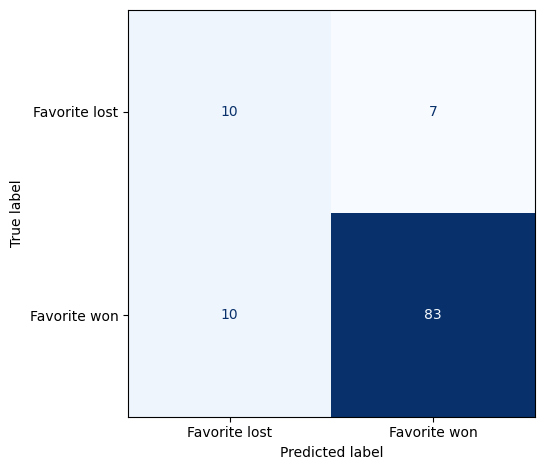

In [43]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    ConfusionMatrixDisplay,
)

# predict winner and get probability of favorite 
y_pred = nb_multinomial.predict(X_test)
y_prob = nb_multinomial.predict_proba(X_test)[:, 1]

# get original probs for test markets 
market_prob = X_test_raw["favorite_probability"]

# check accuracy 
print(f"NB accuracy: {accuracy_score(y_test, y_pred):.1%}")

# baseline: always prediciting that the favorite at the cutoff wins 
print(f"Always predict favorite wins: {y_test.mean():.1%}")

# accuracy of probability (lower is better)
print(f"\nNaive Bayes Brier score: {brier_score_loss(y_test, y_prob):.4f}")
print(f"Market Brier score: {brier_score_loss(y_test, market_prob):.4f}")

# confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Favorite lost", "Favorite won"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
)


plt.tight_layout()
plt.show()